# EDA

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
date_columns = ['cookie_created_at', 'window_start_ts', 'window_end_ts']
train = pd.read_csv('../data/train.csv', parse_dates=date_columns)
test = pd.read_csv('../data/test.csv', parse_dates=date_columns)
events = pd.read_csv('../data/events.csv.gz', parse_dates=['event_ts'])
platform_map = {
    'web': 'web',
    'desktop': 'desktop',
    'android': 'android',
    'ios': 'ios',
    'iphone': 'ios',
}
events['platform'] = (
    events['platform'].str.strip().str.lower().map(platform_map)
)
cookies = pd.concat(
    [train.assign(part='train'), test.assign(part='test')], ignore_index=True
)
events_with_meta = events.merge(cookies, on='cookie_id', how='left')
is_before_window = events_with_meta.event_ts < events_with_meta.window_start_ts
is_after_window = events_with_meta.event_ts >= events_with_meta.window_end_ts
events_with_meta['window_position'] = np.select(
    [is_before_window, is_after_window], ['before', 'after'], 'inside'
)
events_in_window = events_with_meta[
    events_with_meta.window_position == 'inside'
].copy()


def show_table(title, table):
    print(title)
    display(table)


def as_percent(values, digits=1):
    return values.map(
        lambda value: f'{value:.{digits}%}' if pd.notna(value) else ''
    )


def compare_humans_and_bots(cookie_table, metric_names):
    rows = {}
    for column, metric_name in metric_names.items():
        row = {}
        for target, group_name in [(0, 'люди'), (1, 'боты')]:
            values = cookie_table.loc[cookie_table.target == target, column]
            row[(group_name, 'среднее')] = round(values.mean(), 2)
            row[(group_name, 'медиана')] = round(values.median(), 2)
            row[(group_name, '80% кук в диапазоне')] = (
                f'{round(values.quantile(0.1), 2) + 0.0:g} - {round(values.quantile(0.9), 2) + 0.0:g}'
            )
        rows[metric_name] = row
    table = pd.DataFrame(rows).T
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return table.rename_axis('метрика')


def bot_share_table(cookie_table, groups, group_name):
    table = cookie_table.groupby(groups, observed=True).target.agg(
        bot_share='mean', n_cookies='size', n_bots='sum'
    )
    return table.assign(bot_share=as_percent(table.bot_share)).rename_axis(
        group_name
    )


def plot_bot_share(ax, cookie_table, groups, title, xlabel):
    cookie_table.groupby(groups, observed=True).target.mean().plot.bar(
        ax=ax, color='C3', rot=0
    )
    ax.axhline(
        cookie_table.target.mean(),
        color='k',
        linestyle='--',
        label='средняя доля ботов',
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('доля ботов')
    ax.legend()


print(
    'train:',
    train.shape,
    'test:',
    test.shape,
    'все события:',
    events.shape,
    'события внутри окна:',
    events_in_window.shape,
)
print(f'доля ботов в train: {train.target.mean():.4f}')

train: (11091, 5) test: (4909, 4) все события: (328905, 14) события внутри окна: (288126, 20)
доля ботов в train: 0.0811


## 1. Окна наблюдения и история куки

In [2]:
show_table(
    'Длина окна наблюдения',
    (cookies.window_end_ts - cookies.window_start_ts)
    .value_counts()
    .rename('n_cookies'),
)
cookies_by_window_date = (
    cookies.groupby([cookies.window_start_ts.dt.date, 'part'])
    .size()
    .unstack(fill_value=0)
)
cookies_by_window_date['bot_share'] = (
    train.groupby(train.window_start_ts.dt.date).target.mean().round(3)
)
show_table(
    'Число кук в train и test и доля ботов по дате начала окна',
    cookies_by_window_date,
)

Длина окна наблюдения


1 days    16000
Name: n_cookies, dtype: int64

Число кук в train и test и доля ботов по дате начала окна


part,test,train,bot_share
window_start_ts,,,
2026-04-06,0,772,0.088
2026-04-07,0,797,0.074
2026-04-08,0,834,0.084
2026-04-09,0,902,0.073
2026-04-10,0,912,0.090
2026-04-11,0,896,0.088
2026-04-12,0,817,0.082
2026-04-13,0,843,0.063
2026-04-14,0,826,0.085


**Вывод:** Все окна ровно сутки. Train и test разделены по времени: train 06.04-19.04, test 20.04-26.04, значит валидацию делаем по времени, а не случайным сплитом.

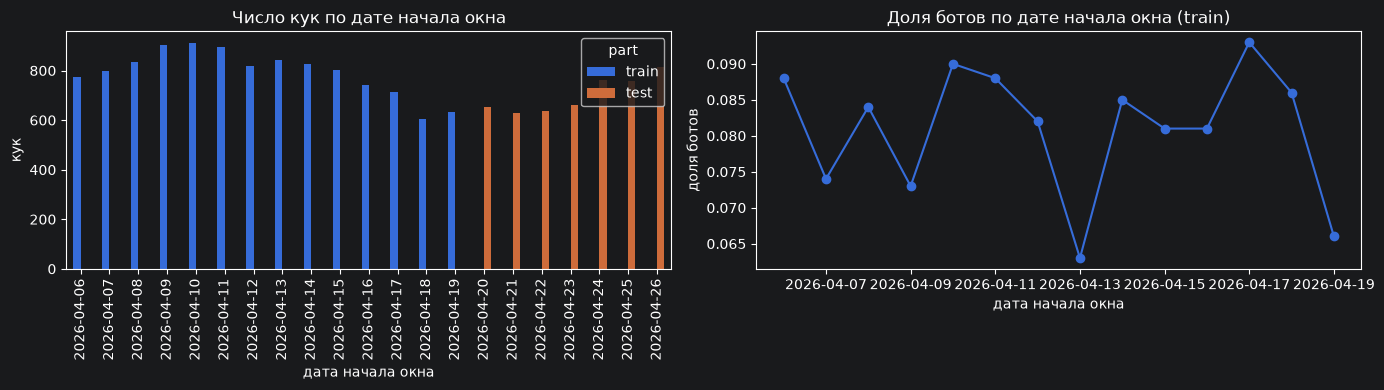

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cookies_by_window_date[['train', 'test']].plot.bar(
    ax=ax[0], title='Число кук по дате начала окна'
)
ax[0].set_xlabel('дата начала окна')
ax[0].set_ylabel('кук')
cookies_by_window_date['bot_share'].plot(
    ax=ax[1], marker='o', title='Доля ботов по дате начала окна (train)'
)
ax[1].set_xlabel('дата начала окна')
ax[1].set_ylabel('доля ботов')
plt.tight_layout()
plt.show()

**Вывод:** Кук в день примерно поровну, доля ботов стабильна (6-9%), явного дрейфа по дням нет.

In [4]:
positions = ['before', 'inside', 'after']
events_by_position = (
    events_with_meta.groupby(['cookie_id', 'window_position'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=positions, fill_value=0)
)
events_by_position = (
    cookies[['cookie_id', 'part', 'target']]
    .merge(events_by_position, on='cookie_id', how='left')
    .fillna(dict.fromkeys(positions, 0))
)
events_by_position['group'] = np.where(
    events_by_position.part == 'test',
    'test',
    'train_target_' + events_by_position.target.astype('Int64').astype(str),
)
position_counts = events_by_position.groupby('group')[positions]
show_table(
    'Среднее число событий на куку до, внутри и после окна',
    position_counts.mean().round(2),
)
show_table(
    'Доля кук, у которых есть хотя бы одно событие до, внутри и после окна',
    position_counts.agg(lambda counts: (counts > 0).mean()).round(3),
)
show_table(
    'Число кук без событий внутри окна',
    (events_by_position.inside == 0)
    .groupby(events_by_position.group)
    .sum()
    .rename('n_cookies'),
)

Среднее число событий на куку до, внутри и после окна


,before,inside,after
group,,,
test,0.0,18.27,0.00
train_target_0,0.0,16.87,2.08
train_target_1,0.0,29.48,21.77


Доля кук, у которых есть хотя бы одно событие до, внутри и после окна


,before,inside,after
group,,,
test,0.0,1.0,0.00
train_target_0,0.0,1.0,0.45
train_target_1,0.0,1.0,0.77


Число кук без событий внутри окна


group
test              0
train_target_0    0
train_target_1    0
Name: n_cookies, dtype: int64

**Вывод:** Событий до окна нет ни у кого. События после окна есть только в train, и у ботов их в 10 раз больше (21.8 против 2.1): это утечка, признаки считаем только по событиям внутри окна.

In [5]:
cookies['cookie_age_days'] = (
    cookies.window_start_ts - cookies.cookie_created_at
).dt.total_seconds() / 86400
show_table(
    'Возраст куки на начало окна в днях, train и test',
    cookies.groupby('part').cookie_age_days.describe().round(2),
)
train_cookies = cookies[cookies.part == 'train'].copy()
train_cookies['target'] = train_cookies.target.astype(int)
cookie_age_labels = [
    'до 1 дня',
    '1-7 дней',
    '7-30 дней',
    '1-3 мес',
    '3-6 мес',
    '6+ мес',
]
train_cookies['cookie_age_bin'] = pd.cut(
    train_cookies.cookie_age_days,
    [0, 1, 7, 30, 90, 180, np.inf],
    right=False,
    labels=cookie_age_labels,
)
show_table(
    'Доля ботов по возрасту куки (train)',
    bot_share_table(train_cookies, 'cookie_age_bin', 'возраст куки'),
)

Возраст куки на начало окна в днях, train и test


,count,mean,std,min,25%,50%,75%,max
part,,,,,,,,
test,4909.0,71.65,68.00,0.02,12.14,58.63,107.64,465.29
train,11091.0,71.87,66.99,0.01,13.11,59.76,108.55,449.28


Доля ботов по возрасту куки (train)


,bot_share,n_cookies,n_bots
возраст куки,,,
до 1 дня,18.0%,1296,233
1-7 дней,15.0%,1336,200
7-30 дней,5.0%,939,47
1-3 мес,5.6%,3846,217
3-6 мес,5.6%,2882,161
6+ мес,5.2%,792,41


**Вывод:** Возраст кук в train и test распределён одинаково. На свежих куках (до 7 дней) ботов 15-18%, на остальных около 5%. Видимо потому что их банят

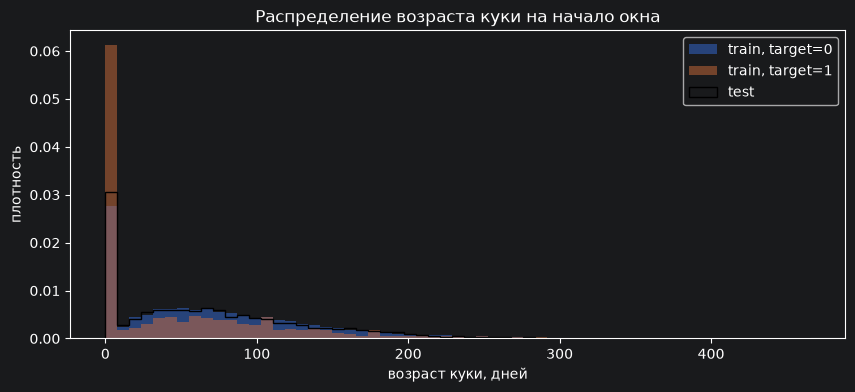

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
age_bins = np.linspace(
    cookies.cookie_age_days.min(), cookies.cookie_age_days.max(), 60
)
for target, group in train_cookies.groupby('target'):
    ax.hist(
        group.cookie_age_days,
        bins=age_bins,
        density=True,
        alpha=0.5,
        label=f'train, target={target}',
    )
ax.hist(
    cookies.loc[cookies.part == 'test', 'cookie_age_days'],
    bins=age_bins,
    density=True,
    histtype='step',
    color='k',
    label='test',
)
ax.set_title('Распределение возраста куки на начало окна')
ax.set_xlabel('возраст куки, дней')
ax.set_ylabel('плотность')
ax.legend()
plt.show()

**Вывод:** У ботов заметный пик на совсем молодых куках, у людей возраст размазан до нескольких месяцев.

## 2. Объём и воронка (только события внутри окна)

In [7]:
train_events = events_in_window[events_in_window.part == 'train'].copy()
train_events['target'] = train_events.target.astype(int)
train_cookies['n_events'] = train_cookies.cookie_id.map(
    train_events.groupby('cookie_id').size()
)
show_table(
    'Число событий в окне на куку: люди против ботов',
    compare_humans_and_bots(train_cookies, {'n_events': 'событий в окне'}),
)
n_events_labels = ['1-2', '3-4', '5-9', '10-19', '20-39', '40+']
train_cookies['n_events_bin'] = pd.cut(
    train_cookies.n_events,
    [1, 3, 5, 10, 20, 40, np.inf],
    right=False,
    labels=n_events_labels,
)
print(f'в среднем по train ботов {train_cookies.target.mean():.1%}')
show_table(
    'Доля ботов в зависимости от числа событий в окне',
    bot_share_table(train_cookies, 'n_events_bin', 'событий в окне'),
)

Число событий в окне на куку: люди против ботов


люди                                боты                            
               среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                               
событий в окне   16.87    12.0              3 - 37   29.48    20.0            6 - 67.2

в среднем по train ботов 8.1%
Доля ботов в зависимости от числа событий в окне


,bot_share,n_cookies,n_bots
событий в окне,,,
1-2,2.2%,637,14
3-4,2.5%,1086,27
5-9,5.0%,2644,133
10-19,7.9%,3258,258
20-39,10.8%,2355,255
40+,19.1%,1111,212


**Вывод:** Боты активнее: медиана 20 событий против 12 у людей. Доля ботов монотонно растёт с числом событий: 2% при 1-4 событиях и 19% при 40+, но диапазоны сильно пересекаются.

In [8]:
train_target = train.set_index('cookie_id').target
event_type_share = pd.crosstab(
    train_events.cookie_id, train_events.event_name, normalize='index'
).join(train_target)
show_table(
    'Средняя доля каждого типа события среди событий куки, по target',
    event_type_share.groupby('target').mean().T.round(3),
)
has_event_type = (
    pd.crosstab(train_events.cookie_id, train_events.event_name)
    .gt(0)
    .join(train_target)
)

Средняя доля каждого типа события среди событий куки, по target


target,0,1
contact_chat_open,0.017,0.018
contact_message_sent,0.008,0.010
contact_phone_show,0.031,0.033
favorite_add,0.069,0.033
item_view,0.364,0.425
login,0.023,0.010
photo_swipe,0.127,0.078
search_results_view,0.308,0.331
seller_page_view,0.053,0.061


**Вывод:** Люди чаще добавляют в избранное (0.069 против 0.033), листают фото (0.127 против 0.078) и логинятся. Боты чаще смотрят объявления и страницы продавцов (похоже на парсинг)

In [9]:
event_flags = train_events.assign(
    captcha_count=train_events.event_name == 'captcha_shown',
    login_count=train_events.event_name == 'login',
)
captcha_and_login_counts = (
    event_flags.groupby('cookie_id')[['captcha_count', 'login_count']]
    .sum()
    .join(train_target)
)
show_table(
    'Доля ботов по числу показов капчи внутри окна',
    bot_share_table(
        captcha_and_login_counts,
        captcha_and_login_counts.captcha_count.clip(upper=5),
        'показов капчи (5 = 5+)',
    ),
)
show_table(
    'Доля ботов по числу логинов внутри окна',
    bot_share_table(
        captcha_and_login_counts,
        captcha_and_login_counts.login_count.clip(upper=5),
        'логинов (5 = 5+)',
    ),
)
has_captcha = captcha_and_login_counts.captcha_count.gt(0).rename(
    'has_captcha'
)
has_login = captcha_and_login_counts.login_count.gt(0).rename('has_login')
show_table(
    'Доля ботов в зависимости от наличия капчи и логина внутри окна',
    as_percent(
        pd.crosstab(
            has_captcha,
            has_login,
            values=captcha_and_login_counts.target,
            aggfunc='mean',
        )
    ),
)

Доля ботов по числу показов капчи внутри окна


,bot_share,n_cookies,n_bots
показов капчи (5 = 5+),,,
0,8.1%,11091,899


Доля ботов по числу логинов внутри окна


,bot_share,n_cookies,n_bots
логинов (5 = 5+),,,
0,8.9%,8178,726
1,6.7%,2176,145
2,4.3%,537,23
3,2.5%,160,4
4,3.1%,32,1
5,0.0%,8,0


Доля ботов в зависимости от наличия капчи и логина внутри окна


has_login,False,True
has_captcha,,
False,8.9%,5.9%


**Вывод:** Внутри окна капчи нет ни у одной куки. Логин работает как маркер человека: чем больше логинов, тем меньше ботов.

In [10]:
web_desktop_events = train_events[
    train_events.platform.isin(['desktop', 'web'])
].assign(pointer_missing=lambda frame: frame.pointer_x.isna())
pointer_by_cookie = (
    web_desktop_events.groupby(['cookie_id', 'platform', 'target'])
    .pointer_missing.agg(pointer_missing_share='mean', n_events='size')
    .reset_index()
)
pointer_missing_by_platform = pointer_by_cookie.pivot_table(
    index='platform',
    columns='target',
    values='pointer_missing_share',
    aggfunc='mean',
)
show_table(
    'Средняя доля событий без координат указателя на куку (desktop и web)',
    pointer_missing_by_platform.round(3),
)
pointer_by_cookie['pointer_missing_bucket'] = pd.cut(
    pointer_by_cookie.pointer_missing_share,
    [-0.001, 0, 0.999, 1],
    labels=['никогда', 'частично', 'всегда'],
)
bucket_distribution = pd.crosstab(
    [pointer_by_cookie.platform, pointer_by_cookie.target],
    pointer_by_cookie.pointer_missing_bucket,
    normalize='index',
)
show_table(
    'Как часто у куки нет координат указателя: распределение кук по платформе и target',
    as_percent(bucket_distribution),
)

Средняя доля событий без координат указателя на куку (desktop и web)


target,0,1
platform,,
desktop,0.325,0.588
web,0.325,0.596


Как часто у куки нет координат указателя: распределение кук по платформе и target


pointer_missing_bucket никогда частично всегда
platform target                               
desktop  0               57.4%    12.8%  29.8%
         1               34.2%     8.6%  57.1%
web      0               43.0%    28.1%  28.9%
         1               20.2%    22.4%  57.3%

**Вывод:** У ботов чаще нет координат указателя

## 3. Время

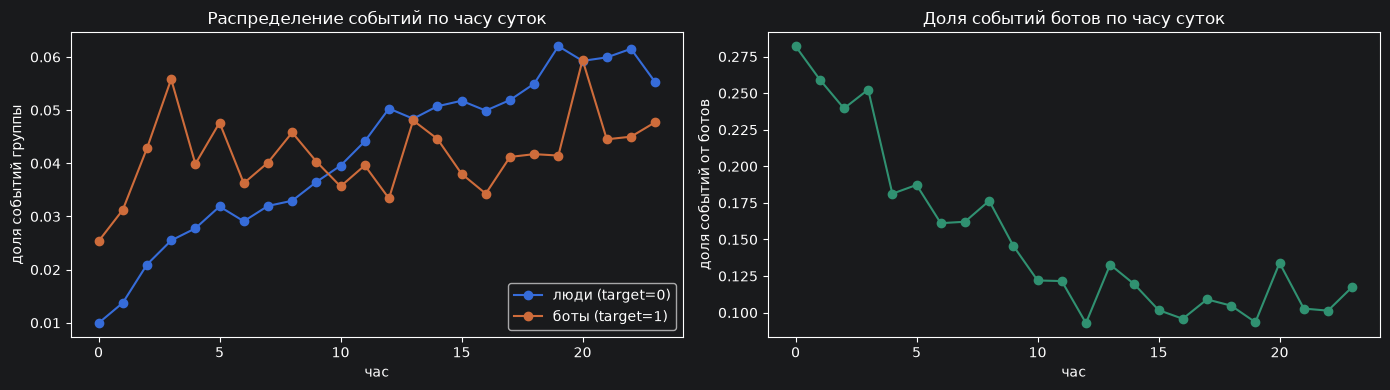

In [11]:
train_events = train_events.sort_values(['cookie_id', 'event_ts'])
train_events['hour'] = train_events.event_ts.dt.hour
events_by_hour = pd.crosstab(
    train_events.hour, train_events.target, normalize='columns'
)
bot_share_by_hour = train_events.groupby('hour').target.mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
events_by_hour.plot(
    ax=ax[0], marker='o', title='Распределение событий по часу суток'
)
ax[0].set_xlabel('час')
ax[0].set_ylabel('доля событий группы')
ax[0].legend(['люди (target=0)', 'боты (target=1)'])
bot_share_by_hour.plot(
    ax=ax[1], marker='o', color='C3', title='Доля событий ботов по часу суток'
)
ax[1].set_xlabel('час')
ax[1].set_ylabel('доля событий от ботов')
plt.tight_layout()
plt.show()

**Вывод:** Люди активны в основном днём и вечером, ночью почти не заходят. У ботов активность ровная по суткам, поэтому ночью события ботов составляют 20-28% всех событий, а днём около 10%.

In [12]:
night_hours = range(6)
is_night = train_events.hour.isin(night_hours)
train_cookies['night_event_share'] = train_cookies.cookie_id.map(
    is_night.groupby(train_events.cookie_id).mean()
)
show_table(
    'Средняя доля ночных событий (0-6 ч) на куку по target',
    train_cookies.groupby('target').night_event_share.mean().round(3),
)
night_share_labels = ['0', 'до 25%', '25-50%', '50-99%', '100%']
train_cookies['night_share_bin'] = pd.cut(
    train_cookies.night_event_share,
    [0, 1e-9, 0.25, 0.5, 1, np.inf],
    right=False,
    labels=night_share_labels,
)
show_table(
    'Доля ботов по доле ночных событий куки',
    bot_share_table(train_cookies, 'night_share_bin', 'доля ночных событий'),
)

Средняя доля ночных событий (0-6 ч) на куку по target


target
0    0.135
1    0.222
Name: night_event_share, dtype: float64

Доля ботов по доле ночных событий куки


,bot_share,n_cookies,n_bots
доля ночных событий,,,
0,7.1%,8846,625
до 25%,10.3%,378,39
25-50%,12.3%,318,39
50-99%,12.1%,496,60
100%,12.9%,1053,136


**Вывод:** У большинства кук ночных событий нет вообще. Если хоть одно ночное событие есть, доля ботов растёт с 7% до 10-13%: признак полезный, но слабый.

In [13]:
train_events['gap_seconds'] = (
    train_events.groupby('cookie_id').event_ts.diff().dt.total_seconds()
)
gap_stats = train_events.groupby('cookie_id').gap_seconds.agg(
    gap_median_seconds='median',
    gap_min_seconds='min',
    gap_mean_seconds='mean',
    gap_std_seconds='std',
    n_gaps='count',
)
gap_stats['gap_cv'] = gap_stats.gap_std_seconds / gap_stats.gap_mean_seconds
train_cookies = train_cookies.drop(
    columns=gap_stats.columns, errors='ignore'
).join(gap_stats, on='cookie_id')
cookies_with_gaps = train_cookies[train_cookies.n_gaps >= 2].copy()
print(
    'кук хотя бы с 3 событиями (есть 2+ интервала):',
    len(cookies_with_gaps),
    'из',
    len(train_cookies),
)
gap_metrics = {
    'gap_median_seconds': 'медианный интервал, с',
    'gap_min_seconds': 'минимальный интервал, с',
    'gap_cv': 'CV интервалов',
}
show_table(
    'Интервалы между соседними событиями куки: люди против ботов',
    compare_humans_and_bots(cookies_with_gaps, gap_metrics),
)

кук хотя бы с 3 событиями (есть 2+ интервала): 10454 из 11091
Интервалы между соседними событиями куки: люди против ботов


люди                                боты                            
                        среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                                        
медианный интервал, с    188.44    59.0          24.5 - 175   98.47    24.0             8 - 311
минимальный интервал, с   21.94     5.0              0 - 35   34.59     3.0            0 - 57.6
CV интервалов              2.04    2.06         0.78 - 3.16    2.67    2.62         0.55 - 4.58

**Вывод:** Типичный бот делает действия в 2.5 раза чаще человека: медианный интервал 24 с против 59 с. При этом у ботов разброс шире в обе стороны (80% ботов от 8 до 311 с, людей от 25 до 175 с), то есть есть и быстрые, и очень медленные боты. CV у ботов в среднем выше: интервалы у них более рваные, пачки запросов и длинные паузы.

Доля ботов в зависимости от медианного интервала между событиями куки


,bot_share,n_cookies,n_bots
медианный интервал,,,
до 10 с,61.1%,193,118
10-20 с,33.3%,708,236
20-30 с,14.6%,1130,165
30-60 с,5.0%,3537,178
1-2 мин,1.9%,3029,58
2-5 мин,3.0%,1230,37
5+ мин,14.8%,627,93


Доля ботов в зависимости от CV интервалов (0 = идеально ровные интервалы, больше 1 = пачки и паузы)


,bot_share,n_cookies,n_bots
CV интервалов,,,
до 0.5,19.6%,408,80
0.5-1,8.0%,1273,102
1-1.5,3.2%,1197,38
1.5-2,4.1%,1953,80
2-2.5,5.0%,2307,115
2.5-3,6.3%,1678,106
3-4,15.7%,1290,202
4+,46.6%,348,162


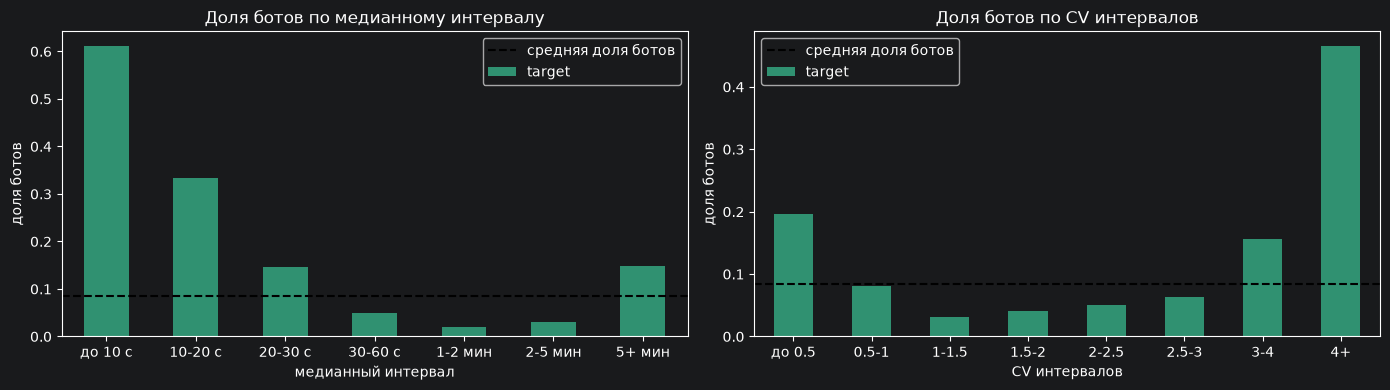

In [14]:
gap_median_labels = [
    'до 10 с',
    '10-20 с',
    '20-30 с',
    '30-60 с',
    '1-2 мин',
    '2-5 мин',
    '5+ мин',
]
cookies_with_gaps['gap_median_bin'] = pd.cut(
    cookies_with_gaps.gap_median_seconds,
    [0, 10, 20, 30, 60, 120, 300, np.inf],
    right=False,
    labels=gap_median_labels,
)
gap_cv_labels = [
    'до 0.5',
    '0.5-1',
    '1-1.5',
    '1.5-2',
    '2-2.5',
    '2.5-3',
    '3-4',
    '4+',
]
cookies_with_gaps['gap_cv_bin'] = pd.cut(
    cookies_with_gaps.gap_cv,
    [0, 0.5, 1, 1.5, 2, 2.5, 3, 4, np.inf],
    right=False,
    labels=gap_cv_labels,
)
show_table(
    'Доля ботов в зависимости от медианного интервала между событиями куки',
    bot_share_table(cookies_with_gaps, 'gap_median_bin', 'медианный интервал'),
)
show_table(
    'Доля ботов в зависимости от CV интервалов (0 = идеально ровные интервалы, больше 1 = пачки и паузы)',
    bot_share_table(cookies_with_gaps, 'gap_cv_bin', 'CV интервалов'),
)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_bot_share(
    ax[0],
    cookies_with_gaps,
    'gap_median_bin',
    'Доля ботов по медианному интервалу',
    'медианный интервал',
)
plot_bot_share(
    ax[1],
    cookies_with_gaps,
    'gap_cv_bin',
    'Доля ботов по CV интервалов',
    'CV интервалов',
)
plt.tight_layout()
plt.show()

**Вывод:** Самый сильный временной сигнал. Среди кук с медианным интервалом до 10 с ботов 61%, 10-20 с ботов 33%, а при 1-5 минутах всего 2-3%. Но при паузах 5+ минут ботов снова 15%: есть медленные боты, которые специально выжидают. С CV то же самое: слишком ровные интервалы (CV до 0.5) дают 20% ботов, очень рваные (CV 4+) дают 47%, у людей CV обычно 1-3.

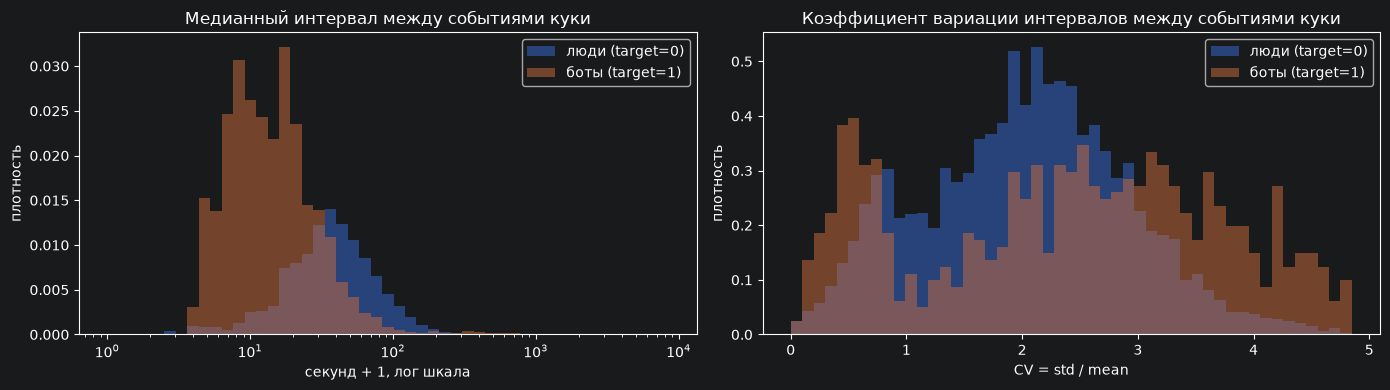

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
median_gap_bins = np.logspace(
    0, np.log10(cookies_with_gaps.gap_median_seconds.max() + 1), 50
)
cv_bins = np.linspace(0, cookies_with_gaps.gap_cv.quantile(0.99), 50)
for target, group in cookies_with_gaps.groupby('target'):
    label = 'боты (target=1)' if target else 'люди (target=0)'
    ax[0].hist(
        group.gap_median_seconds + 1,
        bins=median_gap_bins,
        density=True,
        alpha=0.5,
        label=label,
    )
    ax[1].hist(
        group.gap_cv, bins=cv_bins, density=True, alpha=0.5, label=label
    )
ax[0].set_xscale('log')
ax[0].set_title('Медианный интервал между событиями куки')
ax[0].set_xlabel('секунд + 1, лог шкала')
ax[0].set_ylabel('плотность')
ax[1].set_title('Коэффициент вариации интервалов между событиями куки')
ax[1].set_xlabel('CV = std / mean')
ax[1].set_ylabel('плотность')
for axis in ax:
    axis.legend()
plt.tight_layout()
plt.show()

**Вывод:** На гистограммах видно то же самое: у ботов распределения шире и с тяжёлыми хвостами с обеих сторон, у людей компактный горб посередине.

In [16]:
train_events['is_zero_second'] = train_events.event_ts.dt.second == 0
train_events['is_same_ts_as_previous'] = train_events.gap_seconds == 0
timestamp_flag_names = {
    'is_zero_second': 'zero_second_share',
    'is_same_ts_as_previous': 'same_ts_share',
}
timestamp_flags = (
    train_events.groupby('cookie_id')[list(timestamp_flag_names)]
    .mean()
    .rename(columns=timestamp_flag_names)
)
train_cookies = train_cookies.drop(
    columns=timestamp_flags.columns, errors='ignore'
).join(timestamp_flags, on='cookie_id')
show_table(
    'Доля событий ровно в :00 секунд и с тем же таймстемпом, что у предыдущего события (по событиям, ожидание для :00 около 1/60 = 0.017)',
    train_events.groupby('target')[list(timestamp_flag_names)].mean().round(4),
)

Доля событий ровно в :00 секунд и с тем же таймстемпом, что у предыдущего события (по событиям, ожидание для :00 около 1/60 = 0.017)


,is_zero_second,is_same_ts_as_previous
target,,
0,0.0176,0.0206
1,0.0183,0.0165


**Вывод:** Событий ровно в :00 секунд у обеих групп около 1/60, как у случайного времени, одинаковые таймстемпы тоже встречаются одинаково редко. Округления времени и пачек запросов в одну секунду нет, признаки бесполезны.

In [17]:
events_by_cookie = train_events.groupby('cookie_id')
activity_span = pd.DataFrame(
    {
        'active_hours': events_by_cookie.hour.nunique(),
        'max_gap_hours': events_by_cookie.gap_seconds.max() / 3600,
    }
)
activity_span['session_span_hours'] = (
    events_by_cookie.event_ts.max() - events_by_cookie.event_ts.min()
).dt.total_seconds() / 3600
train_cookies = train_cookies.drop(
    columns=activity_span.columns, errors='ignore'
).join(activity_span, on='cookie_id')
activity_metrics = {
    'active_hours': 'активных часов',
    'session_span_hours': 'от первого до последнего события, ч',
    'max_gap_hours': 'самый длинный перерыв, ч',
}
show_table(
    'Число активных часов, длительность активности и самый длинный перерыв: люди против ботов',
    compare_humans_and_bots(train_cookies, activity_metrics),
)
active_hours_order = [str(hours) for hours in range(1, 12)] + ['12+']
train_cookies['active_hours_bin'] = pd.Categorical(
    train_cookies.active_hours.clip(upper=12).astype(str).replace('12', '12+'),
    active_hours_order,
)
session_span_labels = [
    '0 (одна секунда)',
    'до 15 мин',
    '15 мин - 1 ч',
    '1-3 ч',
    '3-6 ч',
    '6-12 ч',
    '12+ ч',
]
train_cookies['session_span_bin'] = pd.cut(
    train_cookies.session_span_hours,
    [0, 1e-9, 0.25, 1, 3, 6, 12, np.inf],
    right=False,
    labels=session_span_labels,
)
show_table(
    'Доля ботов в зависимости от числа активных часов в окне',
    bot_share_table(train_cookies, 'active_hours_bin', 'активных часов'),
)
show_table(
    'Доля ботов в зависимости от длительности активности (от первого до последнего события)',
    bot_share_table(
        train_cookies, 'session_span_bin', 'длительность активности'
    ),
)

Число активных часов, длительность активности и самый длинный перерыв: люди против ботов


люди                                боты                            
                                    среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                                                    
активных часов                         3.13     3.0               1 - 6    3.22     3.0               1 - 6
от первого до последнего события, ч    3.23    2.31         0.06 - 7.81    3.36    2.53          0.1 - 7.87
самый длинный перерыв, ч               1.38    1.64          0.03 - 2.4    1.41    1.68         0.02 - 2.38

Доля ботов в зависимости от числа активных часов в окне


,bot_share,n_cookies,n_bots
активных часов,,,
1,5.8%,2627,152
2,9.1%,2819,257
3,9.2%,2086,192
4,8.2%,1334,110
5,8.5%,812,69
6,9.7%,487,47
7,9.9%,345,34
8,6.4%,218,14
9,8.6%,139,12


Доля ботов в зависимости от длительности активности (от первого до последнего события)


,bot_share,n_cookies,n_bots
длительность активности,,,
0 (одна секунда),1.9%,259,5
до 15 мин,6.1%,2179,133
15 мин - 1 ч,9.9%,974,96
1-3 ч,8.4%,3208,270
3-6 ч,9.4%,2606,244
6-12 ч,8.5%,1559,133
12+ ч,5.9%,306,18


**Вывод:** Число активных часов, длительность активности и самый длинный перерыв у людей и ботов почти совпадают. Сигнала почти нет, только куки с одним событием или нулевой длительностью почти всегда люди (2% ботов).

## 4. User-Agent

In [18]:
user_agents = pd.DataFrame(
    {'user_agent': events_in_window.user_agent.unique()}
)
automation_libraries = (
    r'^(python-requests|python-urllib3|curl|Go-http-client|node-fetch|Scrapy)/'
)
browser_rules = {
    'headless_chrome': r'HeadlessChrome/(\d+)',
    'yandex_browser': r'YaBrowser/23\.(\d+)',
    'firefox': r'Firefox/(\d+)',
    'native_app': r'^(?!Mozilla)[A-Za-z]+/(\d+)\.\d+ \((?:Android|iPhone)',
    'safari': r'Version/(\d+)',
    'chrome': r'Chrome/(\d+)',
}
user_agents['browser_family'] = user_agents.user_agent.str.extract(
    automation_libraries
)[0]
user_agents['browser_version'] = np.nan
for family, pattern in browser_rules.items():
    version = user_agents.user_agent.str.extract(pattern)[0].astype(float)
    is_new_match = user_agents.browser_family.isna() & version.notna()
    user_agents.loc[is_new_match, 'browser_family'] = family
    user_agents.loc[is_new_match, 'browser_version'] = version[is_new_match]
os_patterns = {
    'windows': 'Windows',
    'macos': 'Macintosh',
    'android': 'Android',
    'ios': 'iPhone|iOS',
    'linux': 'Linux',
}
user_agents['os_name'] = np.select(
    [
        user_agents.user_agent.str.contains(pattern)
        for pattern in os_patterns.values()
    ],
    list(os_patterns),
    'unknown',
)
user_agents['os_version'] = user_agents.user_agent.str.extract(
    r'(?:Android |iPhone OS |iOS )(\d+)'
)[0].astype('Int64')
automation_families = [
    'python-requests',
    'python-urllib3',
    'curl',
    'Go-http-client',
    'node-fetch',
    'Scrapy',
    'headless_chrome',
]
ua_kind_conditions = [
    user_agents.browser_family.isin(automation_families),
    user_agents.browser_family == 'native_app',
    user_agents.os_name.isin(['android', 'ios']),
]
user_agents['ua_kind'] = np.select(
    ua_kind_conditions,
    ['automation', 'native_app', 'mobile_browser'],
    'desktop_browser',
)
user_agent_columns = user_agents.columns.drop('user_agent')
events_in_window = events_in_window.drop(
    columns=user_agent_columns, errors='ignore'
).merge(user_agents, on='user_agent', how='left')
train_events = train_events.drop(
    columns=user_agent_columns, errors='ignore'
).merge(user_agents, on='user_agent', how='left')
print(
    'разных UA:',
    len(user_agents),
    ' не распознано:',
    user_agents.browser_family.isna().sum(),
)
ua_summary = events_in_window.groupby(['ua_kind', 'browser_family']).agg(
    n_user_agents=('user_agent', 'nunique'),
    n_events=('cookie_id', 'size'),
    n_cookies=('cookie_id', 'nunique'),
)
ua_cookies_by_part = events_in_window.pivot_table(
    index=['ua_kind', 'browser_family'],
    columns='part',
    values='cookie_id',
    aggfunc='nunique',
).add_prefix('n_cookies_')
show_table(
    'Виды UA: сколько разных строк UA, событий и кук (train и test)',
    ua_summary.join(ua_cookies_by_part).sort_values(
        'n_events', ascending=False
    ),
)

разных UA: 148  не распознано: 0
Виды UA: сколько разных строк UA, событий и кук (train и test)


n_user_agents  n_events  n_cookies  n_cookies_test  n_cookies_train
ua_kind         browser_family                                                                      
desktop_browser chrome                      28     73221       4470            1399             3071
mobile_browser  chrome                      48     70071       4116            1275             2841
native_app      native_app                  33     52124       3035             894             2141
desktop_browser firefox                     14     38073       2444             762             1682
                yandex_browser              12     33606       2111             652             1459
automation      headless_chrome              4     10435        421             135              286
mobile_browser  safari                       3      4669        269              77              192
automation      python-urllib3               1      1049         48              17               31
                node-fetch                   1      1048         44              11               33
                Scrapy                       1       998         49              14               35
                curl                         1       982         40               8               32
                Go-http-client               1       976         51               9               42
                python-requests              1       874         40              13               27

**Вывод:** Всего 148 разных UA, все распознаются. Основная масса это обычные Chrome, Firefox, Яндекс Браузер, мобильный Chrome и собственное мобильное приложение площадки. UA автоматизации (HeadlessChrome, curl, Scrapy, python-requests и другие) встречаются у 4-5% кук, в train и test в одинаковой доле.

In [19]:
show_table(
    'Сколько событий каждого вида UA пришло с каждой платформы (проверка согласованности UA и platform)',
    pd.crosstab(
        [events_in_window.ua_kind, events_in_window.os_name],
        events_in_window.platform,
    ),
)

Сколько событий каждого вида UA пришло с каждой платформы (проверка согласованности UA и platform)


platform                 android  desktop   ios    web
ua_kind         os_name                               
automation      linux          0     2623     0   7812
                unknown        0     1511     0   4416
native_app      android    42185        0     0      0
                ios            0        0  9939      0
desktop_browser macos          0     9209     0  27761
                windows        0    27425     0  80505
mobile_browser  android    70071        0     0      0
                ios            0        0  4669      0

**Вывод:** UA и platform всегда согласованы: мобильные UA приходят только с android и ios, десктопные и UA автоматизации только с desktop и web. Признак "UA не совпадает с платформой" бесполезен, подделки такого рода в данных нет.

In [20]:
events_by_cookie = train_events.groupby('cookie_id')
user_agent_by_cookie = pd.DataFrame(
    {'n_user_agents': events_by_cookie.user_agent.nunique()}
)
user_agent_by_cookie['automation_event_share'] = (
    train_events.ua_kind.eq('automation')
    .groupby(train_events.cookie_id)
    .mean()
)
user_agent_by_cookie['platform_combination'] = events_by_cookie.platform.agg(
    lambda platforms: ' + '.join(sorted(platforms.unique()))
)
train_cookies = train_cookies.drop(
    columns=user_agent_by_cookie.columns, errors='ignore'
).join(user_agent_by_cookie, on='cookie_id')
train_cookies['automation_ua_bin'] = pd.cut(
    train_cookies.automation_event_share,
    [0, 1e-9, 1, np.inf],
    right=False,
    labels=['нет', 'часть событий', 'все события'],
)
show_table(
    'Доля ботов в зависимости от того, есть ли у куки события с UA автоматизации',
    bot_share_table(
        train_cookies, 'automation_ua_bin', 'события с UA автоматизации'
    ),
)
show_table(
    'Доля ботов в зависимости от числа разных UA у куки внутри окна',
    bot_share_table(train_cookies, 'n_user_agents', 'разных UA'),
)
show_table(
    'Доля ботов в зависимости от набора платформ куки внутри окна',
    bot_share_table(train_cookies, 'platform_combination', 'платформы'),
)

Доля ботов в зависимости от того, есть ли у куки события с UA автоматизации


,bot_share,n_cookies,n_bots
события с UA автоматизации,,,
нет,7.4%,10605,780
все события,24.5%,486,119


Доля ботов в зависимости от числа разных UA у куки внутри окна


,bot_share,n_cookies,n_bots
разных UA,,,
1,8.2%,10295,848
2,0.9%,107,1
3,7.3%,689,50


Доля ботов в зависимости от набора платформ куки внутри окна


,bot_share,n_cookies,n_bots
платформы,,,
android,6.2%,4595,285
desktop,0.0%,51,0
desktop + web,10.9%,5219,567
ios,4.5%,579,26
web,3.2%,647,21


**Вывод:** UA автоматизации поднимает долю ботов в 3 раза (24.5% против 7.4%), но 75% таких кук размечены как люди: разметка это трафик конкретных известных сервисов, а не любой автоматизации. Смены UA внутри окна как признака ротации нет: у кук с 3 UA ботов столько же, сколько в среднем. Куки, которые ходят и с desktop, и с web, чаще боты (10.9%), чем только web (3.2%).

Доля ботов по семейству браузера (берём самый частый UA куки)


bot_share  n_cookies  n_bots
вид UA          браузер                                     
automation      Go-http-client      16.7%         42       7
                Scrapy              25.7%         35       9
                curl                25.0%         32       8
                headless_chrome     26.2%        286      75
                node-fetch          27.3%         33       9
                python-requests     18.5%         27       5
                python-urllib3      19.4%         31       6
native_app      native_app           9.2%       2141     197
desktop_browser chrome               8.9%       2816     252
                firefox              8.4%       1401     118
                yandex_browser       8.2%       1214      99
mobile_browser  chrome               3.7%       2841     105
                safari               4.7%        192       9

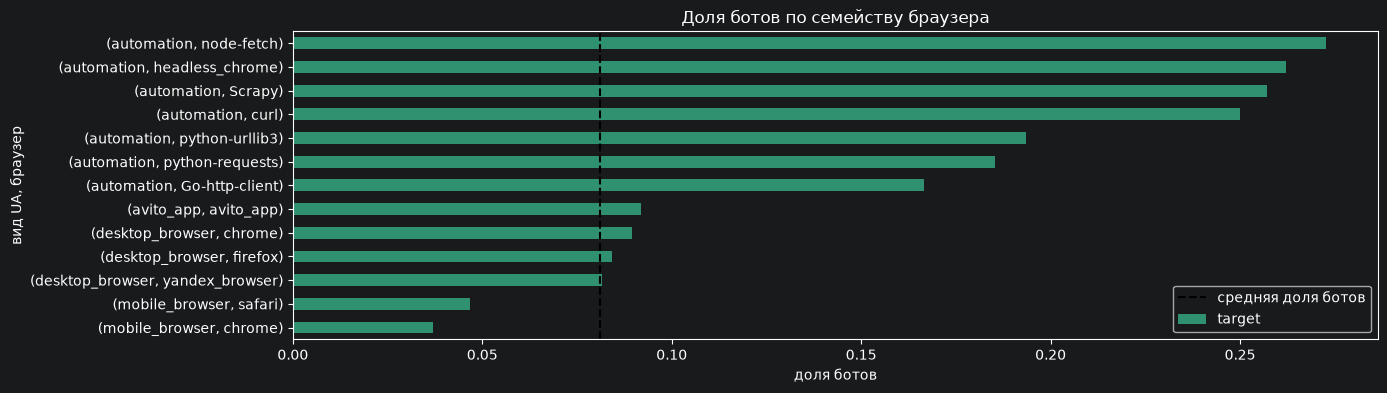

In [21]:
user_agent_counts = (
    train_events.groupby(['cookie_id', 'user_agent'])
    .size()
    .rename('n_events')
    .reset_index()
)
main_user_agent = (
    user_agent_counts.sort_values(
        ['cookie_id', 'n_events'], ascending=[True, False]
    )
    .drop_duplicates('cookie_id')
    .set_index('cookie_id')
    .user_agent
)
main_browser_columns = [
    'ua_kind',
    'browser_family',
    'browser_version',
    'os_name',
    'os_version',
]
main_browser = (
    user_agents.set_index('user_agent')
    .loc[main_user_agent.values, main_browser_columns]
    .set_axis(main_user_agent.index)
)
train_cookies = train_cookies.drop(
    columns=main_browser.columns, errors='ignore'
).join(main_browser, on='cookie_id')
show_table(
    'Доля ботов по семейству браузера (берём самый частый UA куки)',
    bot_share_table(
        train_cookies, ['ua_kind', 'browser_family'], ['вид UA', 'браузер']
    ),
)
fig, ax = plt.subplots(figsize=(14, 4))
train_cookies.groupby(
    ['ua_kind', 'browser_family']
).target.mean().sort_values().plot.barh(ax=ax, color='C3')
ax.axvline(
    train_cookies.target.mean(),
    color='k',
    linestyle='--',
    label='средняя доля ботов',
)
ax.set_title('Доля ботов по семейству браузера')
ax.set_xlabel('доля ботов')
ax.set_ylabel('вид UA, браузер')
ax.legend()
plt.show()

**Вывод:** Все библиотеки автоматизации и HeadlessChrome дают 17-27% ботов. Десктопные браузеры около средней доли (8-9%), мобильный браузер реже (4-5%): на мобильных ботов меньше.

In [22]:
browser_families_with_versions = [
    'chrome',
    'firefox',
    'yandex_browser',
    'native_app',
    'safari',
    'headless_chrome',
]
has_browser_version = train_cookies.browser_family.isin(
    browser_families_with_versions
)
fresh_version_by_family = (
    train_cookies[has_browser_version]
    .groupby('browser_family')
    .browser_version.quantile(0.95)
)
train_cookies['browser_version_lag'] = (
    train_cookies.browser_family.map(fresh_version_by_family)
    - train_cookies.browser_version
)
version_lag_labels = [
    'свежая',
    'на 1-2 версии старее',
    'на 3-5',
    'на 6-8',
    'на 9+',
]
train_cookies['browser_version_lag_bin'] = pd.cut(
    train_cookies.browser_version_lag,
    [-np.inf, 0, 2, 5, 8, np.inf],
    labels=version_lag_labels,
)
show_table(
    'Свежая версия браузера (95-й перцентиль по кукам) для каждого семейства',
    fresh_version_by_family.rename('fresh_version'),
)
show_table(
    'Доля ботов в зависимости от отставания версии браузера от свежей',
    bot_share_table(
        train_cookies, 'browser_version_lag_bin', 'отставание версии'
    ),
)
bot_share_by_family_and_lag = train_cookies[has_browser_version].pivot_table(
    index='browser_family',
    columns='browser_version_lag_bin',
    values='target',
    aggfunc='mean',
    observed=True,
)
show_table(
    'Доля ботов по семейству браузера и отставанию версии',
    as_percent(bot_share_by_family_and_lag),
)
mobile_cookies = train_cookies[train_cookies.os_name.isin(['android', 'ios'])]
show_table(
    'Доля ботов по версии мобильной ОС',
    bot_share_table(
        mobile_cookies, ['os_name', 'os_version'], ['ОС', 'версия']
    ),
)

Свежая версия браузера (95-й перцентиль по кукам) для каждого семейства


browser_family
native_app         122.0
chrome             124.0
firefox            123.0
headless_chrome    124.0
safari              17.0
yandex_browser      11.0
Name: fresh_version, dtype: float64

Доля ботов в зависимости от отставания версии браузера от свежей


,bot_share,n_cookies,n_bots
отставание версии,,,
свежая,8.2%,2536,208
на 1-2 версии старее,9.5%,1620,154
на 3-5,5.8%,2885,167
на 6-8,8.0%,2188,176
на 9+,9.0%,1662,150


Доля ботов по семейству браузера и отставанию версии


browser_version_lag_bin,свежая,на 1-2 версии старее,на 3-5,на 6-8,на 9+
browser_family,,,,,
native_app,12.2%,9.0%,5.8%,,
chrome,5.1%,11.6%,3.9%,6.7%,9.9%
firefox,10.0%,7.0%,8.6%,9.1%,8.1%
headless_chrome,24.1%,,23.9%,32.9%,23.2%
safari,1.5%,6.3%,,,
yandex_browser,12.8%,11.3%,9.1%,6.9%,4.7%


Доля ботов по версии мобильной ОС


bot_share  n_cookies  n_bots
ОС      версия                             
android 11          7.6%       1343     102
        12          5.2%       1254      65
        13          6.9%       1289      89
        14          4.1%        709      29
ios     15          7.6%         66       5
        16          4.1%        244      10
        17          4.1%        269      11

**Вывод:** Отставание версии браузера в целом ничего не даёт. Но у Яндекс Браузера и мобильного приложения картина обратная ожидаемой: на свежих версиях ботов больше (12-13%), на старых меньше (5-6%). Боты не сидят на старых браузерах, а скорее прописывают себе свежий UA. Старый Android слегка чаще у ботов (7.6% на Android 11 против 4.1% на Android 14).

## 5. Контент: объявления, категории, поиск

In [23]:
content_columns = [
    'item_id',
    'item_category',
    'item_location',
    'seller_type',
    'search_query',
    'search_page',
]
field_fill_share = train_events.groupby('event_name')[content_columns].agg(
    lambda values: values.notna().mean()
)
show_table(
    'Доля событий каждого типа, у которых заполнено поле',
    as_percent(field_fill_share, digits=0),
)

Доля событий каждого типа, у которых заполнено поле


,item_id,item_category,item_location,seller_type,search_query,search_page
event_name,,,,,,
contact_chat_open,100%,94%,97%,91%,0%,0%
contact_message_sent,100%,94%,97%,91%,0%,0%
contact_phone_show,100%,94%,97%,91%,0%,0%
favorite_add,100%,94%,97%,91%,0%,0%
item_view,100%,94%,97%,91%,0%,0%
login,0%,0%,0%,0%,0%,0%
photo_swipe,100%,94%,97%,91%,0%,0%
search_results_view,0%,94%,97%,0%,100%,100%
seller_page_view,100%,94%,97%,91%,0%,0%


**Вывод:** Поля заполнены по логике событий: у событий с объявлением есть item_id, категория, локация и тип продавца, у поиска запрос, страница, категория и локация, у логина ничего. Небольшие пропуски есть и там, где поле должно быть (категория 6%, локация 3%, тип продавца 9%).

In [24]:
train_events = train_events.sort_values(['cookie_id', 'event_ts'])
item_events = train_events[train_events.item_id.notna()]
search_events = train_events[train_events.event_name == 'search_results_view']
events_by_cookie = train_events.groupby('cookie_id')
content_diversity = pd.DataFrame(
    {
        'n_unique_categories': events_by_cookie.item_category.nunique(),
        'n_unique_locations': events_by_cookie.item_location.nunique(),
    }
)
content_diversity['n_item_events'] = item_events.groupby('cookie_id').size()
content_diversity['n_unique_items'] = item_events.groupby(
    'cookie_id'
).item_id.nunique()
content_diversity['n_search_events'] = search_events.groupby(
    'cookie_id'
).size()
content_diversity['n_unique_queries'] = search_events.groupby(
    'cookie_id'
).search_query.nunique()
content_diversity['events_per_item'] = (
    content_diversity.n_item_events / content_diversity.n_unique_items
)
content_diversity['searches_per_query'] = (
    content_diversity.n_search_events / content_diversity.n_unique_queries
)
train_cookies = train_cookies.drop(
    columns=content_diversity.columns, errors='ignore'
).join(content_diversity, on='cookie_id')
content_metrics = {
    'n_unique_items': 'разных объявлений',
    'events_per_item': 'событий на одно объявление',
    'n_unique_categories': 'разных категорий',
    'n_unique_locations': 'разных локаций (городов)',
    'n_unique_queries': 'разных поисковых запросов',
    'searches_per_query': 'просмотров выдачи на один запрос',
}
show_table(
    'Разнообразие контента у куки: люди против ботов',
    compare_humans_and_bots(train_cookies, content_metrics),
)
train_cookies['unique_locations_bin'] = pd.cut(
    train_cookies.n_unique_locations,
    [0, 1, 2, 3, 5, np.inf],
    right=False,
    labels=['0', '1', '2', '3-4', '5+'],
)
train_cookies['events_per_item_bin'] = pd.cut(
    train_cookies.events_per_item,
    [1, 1.01, 1.5, 2, 3, np.inf],
    right=False,
    labels=['ровно 1', '1-1.5', '1.5-2', '2-3', '3+'],
)
print(f'в среднем по train ботов {train_cookies.target.mean():.1%}')
show_table(
    'Доля ботов в зависимости от числа разных локаций, в которых кука смотрела объявления',
    bot_share_table(train_cookies, 'unique_locations_bin', 'разных локаций'),
)
show_table(
    'Доля ботов в зависимости от числа событий на одно объявление (1 = каждое объявление тронуто один раз)',
    bot_share_table(
        train_cookies, 'events_per_item_bin', 'событий на объявление'
    ),
)

Разнообразие контента у куки: люди против ботов


люди                                боты                            
                                 среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                                                 
разных объявлений                   9.07     6.0              2 - 20   13.78    10.0              3 - 29
событий на одно объявление          1.31    1.25            1 - 1.67    1.31    1.25            1 - 1.72
разных категорий                    2.28     2.0               1 - 4    1.79     2.0               1 - 3
разных локаций (городов)            5.88     5.0              1 - 12    9.79     8.0              3 - 19
разных поисковых запросов           4.15     3.0               1 - 8    4.96     4.0               1 - 9
просмотров выдачи на один запрос    1.28     1.0            1 - 1.83    1.93     1.5            1 - 3.33

в среднем по train ботов 8.1%
Доля ботов в зависимости от числа разных локаций, в которых кука смотрела объявления


,bot_share,n_cookies,n_bots
разных локаций,,,
0,0.0%,15,0
1,1.8%,1066,19
2,1.9%,1550,29
3-4,5.2%,2618,135
5+,12.3%,5842,716


Доля ботов в зависимости от числа событий на одно объявление (1 = каждое объявление тронуто один раз)


,bot_share,n_cookies,n_bots
событий на объявление,,,
ровно 1,6.8%,2696,184
1-1.5,9.0%,5610,503
1.5-2,9.0%,1949,176
2-3,5.9%,597,35
3+,1.5%,66,1


**Вывод:** Боты смотрят больше разных объявлений (медиана 10 против 6) и прыгают по городам: 8 разных локаций против 5 у людей. Если кука смотрит 1-2 города, ботов всего 2%, если 5 и больше, то 12%. При этом категорий у ботов меньше: они сфокусированы на одной теме и собирают её по многим городам. На один запрос боты смотрят больше страниц выдачи (1.5 против 1). Событий на одно объявление одинаково.

In [25]:
item_views = train_events[train_events.event_name == 'item_view'].copy()
item_views['is_repeat_view'] = item_views.duplicated(['cookie_id', 'item_id'])
items_with_photos = (
    train_events.loc[
        train_events.event_name == 'photo_swipe', ['cookie_id', 'item_id']
    ]
    .drop_duplicates()
    .assign(has_photo_swipe=True)
)
viewed_items = (
    item_views[['cookie_id', 'item_id']]
    .drop_duplicates()
    .merge(items_with_photos, how='left')
    .fillna({'has_photo_swipe': False})
)
item_behaviour = pd.DataFrame(
    {
        'repeat_view_share': item_views.groupby(
            'cookie_id'
        ).is_repeat_view.mean(),
        'viewed_items_with_photo_swipe_share': viewed_items.groupby(
            'cookie_id'
        ).has_photo_swipe.mean(),
    }
)
train_cookies = train_cookies.drop(
    columns=item_behaviour.columns, errors='ignore'
).join(item_behaviour, on='cookie_id')
item_metrics = {
    'repeat_view_share': 'доля повторных просмотров объявлений',
    'viewed_items_with_photo_swipe_share': 'доля просмотренных объявлений, где листали фото',
}
show_table(
    'Как кука смотрит объявления: люди против ботов',
    compare_humans_and_bots(train_cookies, item_metrics),
)
share_bins = [0, 1e-9, 0.25, 0.5, 0.75, 1, np.inf]
share_labels = ['0', 'до 25%', '25-50%', '50-75%', '75-99%', '100%']
train_cookies['photo_swipe_share_bin'] = pd.cut(
    train_cookies.viewed_items_with_photo_swipe_share,
    share_bins,
    right=False,
    labels=share_labels,
)
show_table(
    'Доля ботов в зависимости от того, в скольких просмотренных объявлениях кука листала фото',
    bot_share_table(
        train_cookies, 'photo_swipe_share_bin', 'объявлений с листанием фото'
    ),
)

Как кука смотрит объявления: люди против ботов


люди                                боты                            
                                                среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                                                                
доля повторных просмотров объявлений               0.11     0.0            0 - 0.33    0.15    0.13            0 - 0.34
доля просмотренных объявлений, где листали фото    0.09     0.0            0 - 0.33    0.05     0.0            0 - 0.16

Доля ботов в зависимости от того, в скольких просмотренных объявлениях кука листала фото


,bot_share,n_cookies,n_bots
объявлений с листанием фото,,,
0,8.5%,5685,482
до 25%,12.6%,1742,219
25-50%,4.5%,663,30
50-75%,1.6%,254,4
75-99%,0.0%,4,0
100%,2.2%,134,3


**Вывод:** Люди чаще листают фото в объявлениях: если фото листали хотя бы в четверти объявлений, ботов всего 2-4.5%. Боты чуть чаще открывают одно и то же объявление повторно.

Как кука листает поисковую выдачу: люди против ботов (только куки с поиском)


люди                                боты                            
                                                   среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                                                                   
максимальная страница выдачи                          4.42     4.0               1 - 9     9.3     7.0              2 - 20
доля просмотров выдачи дальше 3-й страницы            0.18     0.1             0 - 0.5    0.34    0.34            0 - 0.67
доля переходов ровно на следующую страницу того...    0.01     0.0               0 - 0    0.02     0.0            0 - 0.06

Доля ботов в зависимости от самой дальней страницы выдачи


,bot_share,n_cookies,n_bots
максимальная страница,,,
1,3.3%,1473,48
2,4.4%,1678,73
3-4,6.0%,2829,171
5-7,7.6%,2436,185
8-12,13.2%,1297,171
13+,46.8%,457,214


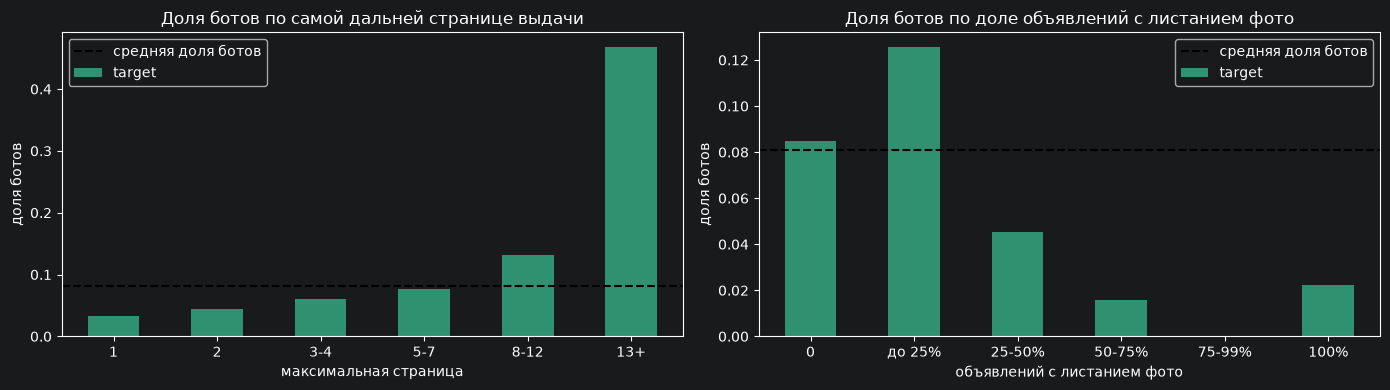

In [26]:
search_by_cookie = search_events.groupby('cookie_id')
search_events = search_events.assign(
    previous_page=search_by_cookie.search_page.shift(),
    previous_query=search_by_cookie.search_query.shift(),
)
search_events['is_next_page'] = (
    search_events.search_page == search_events.previous_page + 1
) & (search_events.search_query == search_events.previous_query)
search_events['is_deep_page'] = search_events.search_page > 3
search_behaviour = search_events.groupby('cookie_id').agg(
    max_search_page=('search_page', 'max'),
    deep_page_share=('is_deep_page', 'mean'),
    next_page_share=('is_next_page', 'mean'),
)
train_cookies = train_cookies.drop(
    columns=search_behaviour.columns, errors='ignore'
).join(search_behaviour, on='cookie_id')
search_metrics = {
    'max_search_page': 'максимальная страница выдачи',
    'deep_page_share': 'доля просмотров выдачи дальше 3-й страницы',
    'next_page_share': 'доля переходов ровно на следующую страницу того же запроса',
}
show_table(
    'Как кука листает поисковую выдачу: люди против ботов (только куки с поиском)',
    compare_humans_and_bots(
        train_cookies[train_cookies.max_search_page.notna()], search_metrics
    ),
)
train_cookies['max_search_page_bin'] = pd.cut(
    train_cookies.max_search_page,
    [1, 2, 3, 5, 8, 13, np.inf],
    right=False,
    labels=['1', '2', '3-4', '5-7', '8-12', '13+'],
)
show_table(
    'Доля ботов в зависимости от самой дальней страницы выдачи',
    bot_share_table(
        train_cookies, 'max_search_page_bin', 'максимальная страница'
    ),
)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_bot_share(
    ax[0],
    train_cookies,
    'max_search_page_bin',
    'Доля ботов по самой дальней странице выдачи',
    'максимальная страница',
)
plot_bot_share(
    ax[1],
    train_cookies,
    'photo_swipe_share_bin',
    'Доля ботов по доле объявлений с листанием фото',
    'объявлений с листанием фото',
)
plt.tight_layout()
plt.show()

**Вывод:** Один из самых сильных признаков: боты уходят глубоко в выдачу. Медианная максимальная страница 7 против 4 у людей, а среди кук, дошедших до 13-й страницы и дальше, ботов 47%. При этом страницы подряд (1, 2, 3...) не листают ни люди, ни боты, так что признак последовательного обхода бесполезен, работает именно глубина.

In [27]:
seller_behaviour = pd.DataFrame(
    {
        'pro_seller_share': item_events.seller_type.eq('pro')
        .groupby(item_events.cookie_id)
        .mean()
    }
)
contact_events = train_events[
    train_events.event_name.str.startswith('contact_')
]
contact_counts = (
    contact_events.groupby('cookie_id')
    .size()
    .reindex(seller_behaviour.index, fill_value=0)
)
seller_behaviour['contacts_per_item_view'] = (
    contact_counts
    / item_views.groupby('cookie_id').size().reindex(seller_behaviour.index)
)
train_cookies = train_cookies.drop(
    columns=seller_behaviour.columns, errors='ignore'
).join(seller_behaviour, on='cookie_id')
seller_metrics = {
    'pro_seller_share': 'доля объявлений от pro продавцов',
    'contacts_per_item_view': 'контактных действий на один просмотр объявления',
}
show_table(
    'Продавцы и контакты: люди против ботов (только куки с событиями по объявлениям)',
    compare_humans_and_bots(
        train_cookies[train_cookies.pro_seller_share.notna()], seller_metrics
    ),
)
train_cookies['pro_seller_share_bin'] = pd.cut(
    train_cookies.pro_seller_share,
    share_bins,
    right=False,
    labels=share_labels,
)
show_table(
    'Доля ботов в зависимости от доли объявлений от pro продавцов',
    bot_share_table(
        train_cookies, 'pro_seller_share_bin', 'объявлений от pro продавцов'
    ),
)

Продавцы и контакты: люди против ботов (только куки с событиями по объявлениям)


люди                                боты                            
                                                среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                                                                
доля объявлений от pro продавцов                   0.37    0.36            0 - 0.67    0.41    0.41         0.18 - 0.67
контактных действий на один просмотр объявления    0.19    0.06             0 - 0.5    0.19    0.03            0 - 0.57

Доля ботов в зависимости от доли объявлений от pro продавцов


,bot_share,n_cookies,n_bots
объявлений от pro продавцов,,,
0,3.3%,1511,50
до 25%,6.8%,1403,95
25-50%,10.1%,4593,462
50-75%,9.1%,2573,235
75-99%,9.7%,393,38
100%,4.3%,445,19


**Вывод:** Тип продавца почти не отличают ботов от людей: доля pro продавцов 0.41 против 0.37, контактов на просмотр одинаково. Массовой выгрузки контактов в данных не видно.

In [28]:
main_category = (
    train_events.dropna(subset=['item_category'])
    .groupby('cookie_id')
    .item_category.agg(lambda categories: categories.value_counts().index[0])
)
train_cookies = train_cookies.drop(
    columns='main_category', errors='ignore'
).join(main_category.rename('main_category'), on='cookie_id')
show_table(
    'Доля ботов по основной категории куки (самая частая категория в её событиях)',
    bot_share_table(train_cookies, 'main_category', 'основная категория'),
)
query_bot_share = (
    search_events.groupby('search_query')
    .agg(
        bot_event_share=('target', 'mean'),
        n_events=('target', 'size'),
        n_cookies=('cookie_id', 'nunique'),
    )
    .sort_values('bot_event_share', ascending=False)
)
extreme_queries = pd.concat([query_bot_share.head(8), query_bot_share.tail(8)])
show_table(
    'Поисковые запросы с самой высокой и самой низкой долей событий от ботов',
    extreme_queries.assign(
        bot_event_share=as_percent(extreme_queries.bot_event_share)
    ),
)

Доля ботов по основной категории куки (самая частая категория в её событиях)


,bot_share,n_cookies,n_bots
основная категория,,,
avtomobili,7.5%,783,59
bytovaya_tehnika,10.2%,693,71
detskie_tovary,6.8%,747,51
elektronika,9.1%,747,68
hobbi,8.0%,739,59
kvartiry_arenda,8.9%,727,65
kvartiry_prodazha,8.6%,721,62
mebel,7.3%,777,57
noutbuki,6.8%,735,50


Поисковые запросы с самой высокой и самой низкой долей событий от ботов


,bot_event_share,n_events,n_cookies
search_query,,,
грузоперевозки,23.7%,519,334
удаленная работа,21.9%,480,320
микроволновка,21.5%,508,359
skoda octavia,21.1%,558,372
джинсы levis,20.4%,589,377
автокресло,20.2%,491,330
самокат взрослый,20.2%,521,346
новостройка,20.0%,551,350
bmw x5,9.8%,550,383


**Вывод:** Основная категория куки почти не влияет (5.5-10% ботов в любой категории). По поисковым запросам разброс заметнее: у некоторых запросов (грузоперевозки, удалённая работа, skoda octavia) 20-24% событий от ботов, у других 7-10%. Можно попробовать target encoding запроса, но аккуратно, внутри фолдов, чтобы не переобучиться.

## 6. Указатель: координаты курсора

событий с координатами: 66243 из 198436


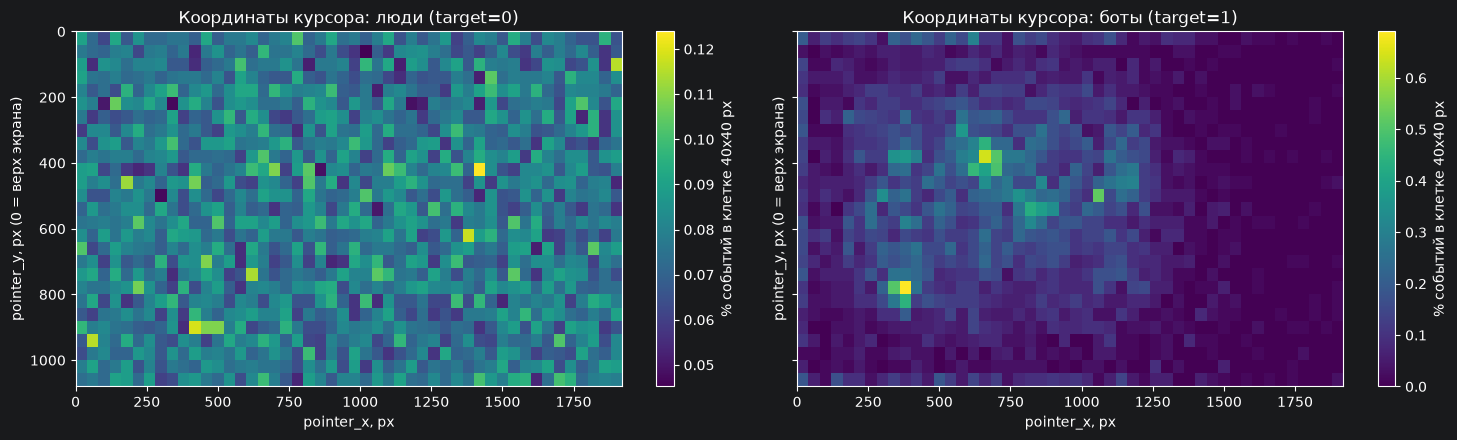

при равномерном курсоре в каждой клетке было бы 0.077% событий


In [29]:
pointer_events = train_events[train_events.pointer_x.notna()].copy()
print('событий с координатами:', len(pointer_events), 'из', len(train_events))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True, sharey=True)
for axis, (target, group) in zip(
    ax, pointer_events.groupby('target'), strict=True
):
    event_weights = np.full(len(group), 100 / len(group))
    *_, image = axis.hist2d(
        group.pointer_x,
        group.pointer_y,
        bins=[48, 27],
        range=[[0, 1920], [0, 1080]],
        weights=event_weights,
        cmap='viridis',
    )
    fig.colorbar(image, ax=axis).set_label('% событий в клетке 40x40 px')
    axis.set_title(
        'Координаты курсора: '
        + ('боты (target=1)' if target else 'люди (target=0)')
    )
    axis.set_xlabel('pointer_x, px')
    axis.set_ylabel('pointer_y, px (0 = верх экрана)')
ax[0].invert_yaxis()
plt.tight_layout()
plt.show()
print(
    f'при равномерном курсоре в каждой клетке было бы {100 / (48 * 27):.3f}% событий'
)

**Вывод:** Цвет показывает, какой процент всех событий группы попал в клетку 40x40 px, шкалы у двух графиков разные. У людей почти все клетки в диапазоне 0.05-0.12%, около 0.077%, как при равномерном курсоре по всему экрану 1920x1080. У ботов события собраны в несколько ярких пятен левее центра: в пиковых клетках до 0.65%, в 8 раз больше равномерного. Правая треть экрана у ботов почти пустая.

In [30]:
is_edge_x = (pointer_events.pointer_x <= 0) | (
    pointer_events.pointer_x >= 1919
)
is_edge_y = (pointer_events.pointer_y <= 0) | (
    pointer_events.pointer_y >= 1080
)
pointer_events['is_screen_edge'] = is_edge_x | is_edge_y
pointer_events['is_round_coordinate'] = (
    pointer_events.pointer_x % 50 == 0
) & (pointer_events.pointer_y % 50 == 0)
pointer_events['is_repeated_point'] = pointer_events.duplicated(
    ['cookie_id', 'pointer_x', 'pointer_y']
)
pointer_aggregations = {
    'n_pointer_events': ('pointer_x', 'size'),
    'pointer_x_mean': ('pointer_x', 'mean'),
    'pointer_x_std': ('pointer_x', 'std'),
    'pointer_y_std': ('pointer_y', 'std'),
    'screen_edge_share': ('is_screen_edge', 'mean'),
    'round_coordinate_share': ('is_round_coordinate', 'mean'),
    'repeated_point_share': ('is_repeated_point', 'mean'),
}
pointer_by_cookie_stats = pointer_events.groupby('cookie_id').agg(
    **pointer_aggregations
)
train_cookies = train_cookies.drop(
    columns=pointer_by_cookie_stats.columns, errors='ignore'
).join(pointer_by_cookie_stats, on='cookie_id')
cookies_with_pointer = train_cookies[
    train_cookies.n_pointer_events >= 3
].copy()
print(
    'кук хотя бы с 3 событиями с координатами:',
    len(cookies_with_pointer),
    'из',
    len(train_cookies),
)
pointer_metrics = {
    'pointer_x_mean': 'средний X, px',
    'pointer_x_std': 'разброс X (std), px',
    'pointer_y_std': 'разброс Y (std), px',
    'screen_edge_share': 'доля точек на краю экрана',
    'round_coordinate_share': 'доля точек с круглыми координатами (кратны 50)',
    'repeated_point_share': 'доля повторов уже встречавшейся точки',
}
show_table(
    'Координаты курсора у куки: люди против ботов (куки с 3+ событиями с координатами)',
    compare_humans_and_bots(cookies_with_pointer, pointer_metrics),
)

кук хотя бы с 3 событиями с координатами: 3759 из 11091
Координаты курсора у куки: люди против ботов (куки с 3+ событиями с координатами)


люди                                боты                            
                                               среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                                                               
средний X, px                                   957.47   965.1       723 - 1179.26  678.71  661.24    325.89 - 1085.58
разброс X (std), px                             543.65  552.62     410.72 - 671.78  219.17  200.55       71.12 - 369.4
разброс Y (std), px                             302.27  308.71     223.82 - 373.85  199.38  200.97      66.39 - 323.63
доля точек на краю экрана                          0.0     0.0               0 - 0     0.1    0.03             0 - 0.3
доля точек с круглыми координатами (кратны 50)     0.0     0.0               0 - 0     0.0     0.0               0 - 0
доля повторов уже встречавшейся точки             0.01     0.0            0 - 0.06    0.01     0.0            0 - 0.05

**Вывод:** Разброс курсора сильно отличает ботов: std по X у людей 553 px (как у равномерного распределения по экрану), у ботов 200 px. Боты иногда ставят курсор ровно на край экрана (0 или 1080/1920), люди почти никогда. Круглые координаты и повторы одной и той же точки встречаются одинаково редко, эти признаки бесполезны. Важно: координаты есть только у desktop и web, куки хотя бы с 3 такими событиями это лишь треть train.

Доля ботов в зависимости от разброса X курсора (для равномерного курсора по экрану 1920 px std около 554)


,bot_share,n_cookies,n_bots
"разброс X, px",,,
до 200,65.6%,189,124
200-300,49.7%,143,71
300-350,25.8%,89,23
350-400,9.8%,123,12
400-450,2.8%,216,6
450-500,0.5%,409,2
500+,0.4%,2590,10


Доля ботов в зависимости от доли точек на краю экрана


,bot_share,n_cookies,n_bots
точек на краю экрана,,,
ни одной,3.3%,3492,115
до 10%,27.5%,131,36
10% и больше,71.3%,136,97


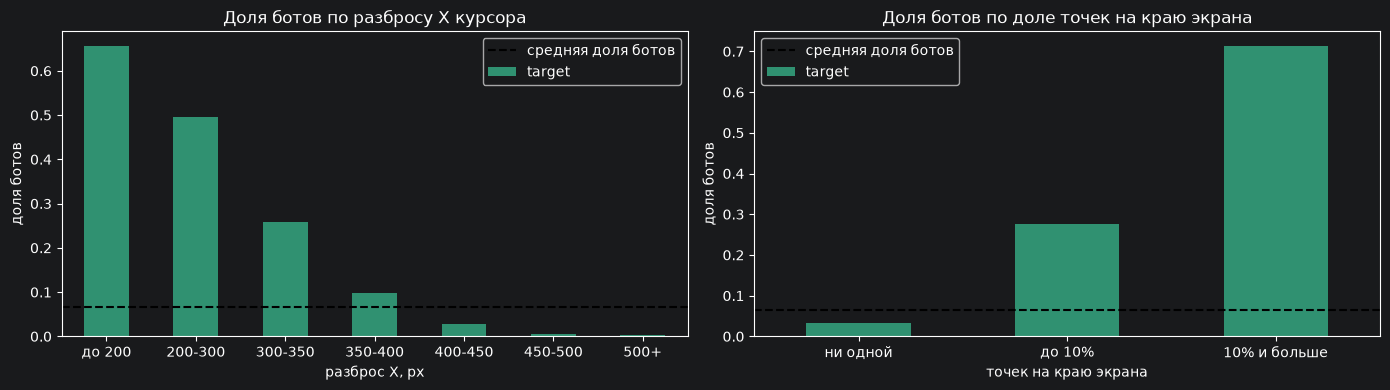

In [31]:
pointer_std_labels = [
    'до 200',
    '200-300',
    '300-350',
    '350-400',
    '400-450',
    '450-500',
    '500+',
]
cookies_with_pointer['pointer_x_std_bin'] = pd.cut(
    cookies_with_pointer.pointer_x_std,
    [0, 200, 300, 350, 400, 450, 500, np.inf],
    right=False,
    labels=pointer_std_labels,
)
cookies_with_pointer['screen_edge_bin'] = pd.cut(
    cookies_with_pointer.screen_edge_share,
    [0, 1e-9, 0.1, np.inf],
    right=False,
    labels=['ни одной', 'до 10%', '10% и больше'],
)
show_table(
    'Доля ботов в зависимости от разброса X курсора (для равномерного курсора по экрану 1920 px std около 554)',
    bot_share_table(
        cookies_with_pointer, 'pointer_x_std_bin', 'разброс X, px'
    ),
)
show_table(
    'Доля ботов в зависимости от доли точек на краю экрана',
    bot_share_table(
        cookies_with_pointer, 'screen_edge_bin', 'точек на краю экрана'
    ),
)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_bot_share(
    ax[0],
    cookies_with_pointer,
    'pointer_x_std_bin',
    'Доля ботов по разбросу X курсора',
    'разброс X, px',
)
plot_bot_share(
    ax[1],
    cookies_with_pointer,
    'screen_edge_bin',
    'Доля ботов по доле точек на краю экрана',
    'точек на краю экрана',
)
plt.tight_layout()
plt.show()

**Вывод:** Самый сильный признак из найденных. При разбросе X до 200 px ботов 66%, при 200-300 px 50%, а при разбросе 450+ px меньше 1%. Если хотя бы 10% точек лежат на краю экрана, ботов 71%. Вместе эти признаки почти идеально отделяют ботов среди кук с курсором.

## 7. Дополнительные признаки: энтропия по часам и контакты без просмотра

**Энтропия по часам** показывает, насколько равномерно события куки раскиданы по часам суток: 0, если все события в одном часу, 4.58, если поровну во всех 24 часах.

Энтропия распределения событий куки по часам суток: люди против ботов


люди                                боты                            
                                                   среднее медиана 80% кук в диапазоне среднее медиана 80% кук в диапазоне
метрика                                                                                                                   
энтропия по часам, бит (максимум 4.58 = все 24 ...    1.12     1.0            0 - 2.26    1.17    1.09            0 - 2.21

Доля ботов в зависимости от энтропии по часам


,bot_share,n_cookies,n_bots
"энтропия, бит",,,
0 (один час),5.8%,2627,152
0-1,9.8%,2748,270
1-1.5,8.5%,1945,166
1.5-2,8.4%,1977,166
2-2.5,9.0%,1126,101
2.5-3,7.7%,521,40
3+,2.7%,147,4


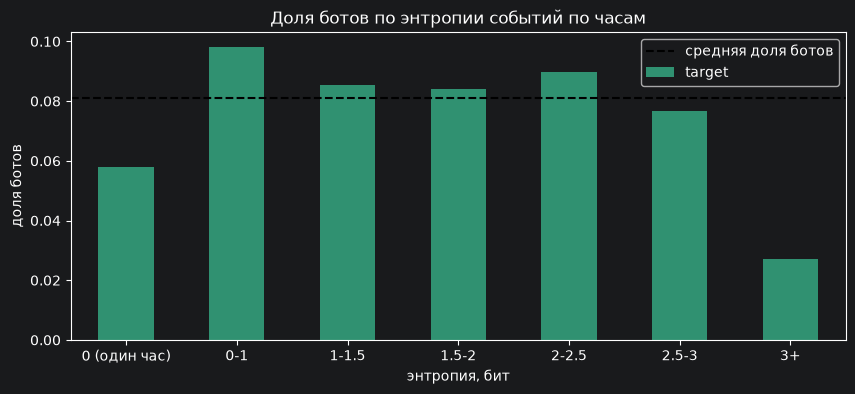

In [32]:
hour_counts = pd.crosstab(train_events.cookie_id, train_events.hour)
hour_probabilities = hour_counts.div(hour_counts.sum(axis=1), axis=0)
hour_entropy = -(
    hour_probabilities
    * np.log2(hour_probabilities.where(hour_probabilities > 0))
).sum(axis=1)
max_possible_entropy = np.log2(
    np.minimum(hour_counts.sum(axis=1), 24)
).replace(0, np.nan)
hour_entropy_stats = pd.DataFrame(
    {
        'hour_entropy': hour_entropy,
        'hour_entropy_normalized': hour_entropy / max_possible_entropy,
    }
)
train_cookies = train_cookies.drop(
    columns=hour_entropy_stats.columns, errors='ignore'
).join(hour_entropy_stats, on='cookie_id')
entropy_metrics = {
    'hour_entropy': 'энтропия по часам, бит (максимум 4.58 = все 24 часа поровну)'
}
show_table(
    'Энтропия распределения событий куки по часам суток: люди против ботов',
    compare_humans_and_bots(train_cookies, entropy_metrics),
)
train_cookies['hour_entropy_bin'] = pd.cut(
    train_cookies.hour_entropy,
    [0, 1e-9, 1, 1.5, 2, 2.5, 3, np.inf],
    right=False,
    labels=['0 (один час)', '0-1', '1-1.5', '1.5-2', '2-2.5', '2.5-3', '3+'],
)
show_table(
    'Доля ботов в зависимости от энтропии по часам',
    bot_share_table(train_cookies, 'hour_entropy_bin', 'энтропия, бит'),
)
fig, ax = plt.subplots(figsize=(10, 4))
plot_bot_share(
    ax,
    train_cookies,
    'hour_entropy_bin',
    'Доля ботов по энтропии событий по часам',
    'энтропия, бит',
)
plt.show()

**Вывод:** Энтропия по часам у людей и ботов почти одинаковая (медиана 1.0 против 1.09): боты не размазывают активность по суткам сильнее людей. Признак слабый (ROC-AUC 0.536)

In [33]:
first_item_view_ts = (
    train_events[train_events.event_name == 'item_view']
    .groupby(['cookie_id', 'item_id'])
    .event_ts.min()
    .rename('first_item_view_ts')
)
contacts_with_view = train_events[
    train_events.event_name.str.startswith('contact_')
].join(first_item_view_ts, on=['cookie_id', 'item_id'])
contacts_with_view[
    'is_without_prior_view'
] = ~contacts_with_view.first_item_view_ts.le(contacts_with_view.event_ts)
show_table(
    'Доля контактных событий без предшествующего просмотра того же объявления, по событиям',
    as_percent(
        contacts_with_view.groupby(['event_name', 'target'])
        .is_without_prior_view.mean()
        .unstack()
    ),
)
contact_without_view_share = (
    contacts_with_view.groupby('cookie_id')
    .is_without_prior_view.mean()
    .rename('contact_without_view_share')
)
train_cookies = train_cookies.drop(
    columns='contact_without_view_share', errors='ignore'
).join(contact_without_view_share, on='cookie_id')
print(
    f'кук с контактными событиями: {train_cookies.contact_without_view_share.notna().sum()} из {len(train_cookies)}'
)
train_cookies['contact_without_view_bin'] = pd.cut(
    train_cookies.contact_without_view_share,
    [0, 1e-9, 0.5, 1, np.inf],
    right=False,
    labels=['0', 'до 50%', '50-99%', '100%'],
)
show_table(
    'Доля ботов в зависимости от доли контактов без предшествующего просмотра объявления (куки с контактами)',
    bot_share_table(
        train_cookies, 'contact_without_view_bin', 'контактов без просмотра'
    ),
)

Доля контактных событий без предшествующего просмотра того же объявления, по событиям


target,0,1
event_name,,
contact_chat_open,89.6%,90.2%
contact_message_sent,88.5%,85.7%
contact_phone_show,89.0%,87.6%


кук с контактными событиями: 5397 из 11091
Доля ботов в зависимости от доли контактов без предшествующего просмотра объявления (куки с контактами)


,bot_share,n_cookies,n_bots
контактов без просмотра,,,
0,10.1%,358,36
до 50%,7.4%,27,2
50-99%,10.9%,781,85
100%,8.1%,4231,344


**Вывод:** Гипотеза не подтвердилась: около 89% контактных событий и у людей, и у ботов идут без предшествующего просмотра того же объявления в окне, доля ботов от этого не зависит (ROC-AUC 0.507). В данных просмотр и контакт не связаны по item_id, поэтому признак бесполезен.

## Итог

Чтобы сравнить признаки между собой, для каждого признака отдельно обучаем маленькое дерево решений (глубина 3) и считаем качество на отложенных днях: train делится на 5 фолдов по дате окна, модель учится на одних днях и предсказывает другие. Дерево ловит и U-образные зависимости. ROC-AUC 0.5 означает, что признак бесполезен. P@R>=0.7 это целевая метрика задачи, для сравнения: у случайного скора она равна доле ботов, 0.081.

In [34]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier

from metric import precision_at_recall

web_desktop_train_events = train_events[
    train_events.platform.isin(['desktop', 'web'])
]
train_cookies['pointer_missing_share'] = train_cookies.cookie_id.map(
    web_desktop_train_events.pointer_x.isna()
    .groupby(web_desktop_train_events.cookie_id)
    .mean()
)
for event_name in [
    'favorite_add',
    'photo_swipe',
    'item_view',
    'seller_page_view',
    'search_results_view',
]:
    train_cookies[f'{event_name}_share'] = train_cookies.cookie_id.map(
        event_type_share[event_name]
    )
train_cookies['login_count'] = train_cookies.cookie_id.map(
    captcha_and_login_counts.login_count
)
for column in ['platform_combination', 'ua_kind', 'browser_family']:
    train_cookies[f'{column}_code'] = (
        train_cookies[column].astype('category').cat.codes
    )
feature_groups = {
    'история куки': ['cookie_age_days'],
    'объём и воронка': [
        'n_events',
        'favorite_add_share',
        'photo_swipe_share',
        'item_view_share',
        'seller_page_view_share',
        'search_results_view_share',
        'login_count',
    ],
    'время': [
        'night_event_share',
        'gap_median_seconds',
        'gap_min_seconds',
        'gap_cv',
        'zero_second_share',
        'same_ts_share',
        'active_hours',
        'session_span_hours',
        'max_gap_hours',
        'hour_entropy',
        'hour_entropy_normalized',
    ],
    'user-agent': [
        'automation_event_share',
        'n_user_agents',
        'platform_combination_code',
        'ua_kind_code',
        'browser_family_code',
        'browser_version_lag',
        'os_version',
    ],
    'контент': [
        'n_unique_items',
        'events_per_item',
        'n_unique_categories',
        'n_unique_locations',
        'n_unique_queries',
        'searches_per_query',
        'repeat_view_share',
        'viewed_items_with_photo_swipe_share',
        'max_search_page',
        'deep_page_share',
        'next_page_share',
        'pro_seller_share',
        'contacts_per_item_view',
        'contact_without_view_share',
    ],
    'указатель': [
        'pointer_missing_share',
        'pointer_x_mean',
        'pointer_x_std',
        'pointer_y_std',
        'screen_edge_share',
        'round_coordinate_share',
        'repeated_point_share',
    ],
}
window_day = train_cookies.window_start_ts.dt.date
single_feature_model = DecisionTreeClassifier(
    max_depth=3, min_samples_leaf=50, random_state=42
)
feature_rows = []
for group_name, features in feature_groups.items():
    for feature in features:
        values = train_cookies[[feature]].astype(float).fillna(-1)
        predicted = cross_val_predict(
            single_feature_model,
            values,
            train_cookies.target,
            groups=window_day,
            cv=GroupKFold(n_splits=5),
            method='predict_proba',
        )[:, 1]
        feature_rows.append(
            {
                'группа': group_name,
                'признак': feature,
                'заполнен у кук': train_cookies[feature].notna().mean(),
                'ROC-AUC': roc_auc_score(train_cookies.target, predicted),
                'P@R>=0.7': precision_at_recall(
                    train_cookies.target, predicted
                ),
            }
        )
feature_ranking = (
    pd.DataFrame(feature_rows)
    .sort_values('ROC-AUC', ascending=False)
    .reset_index(drop=True)
)
show_table(
    'Сила каждого признака по отдельности (дерево глубины 3, фолды по дате окна)',
    feature_ranking.assign(
        **{
            'заполнен у кук': as_percent(
                feature_ranking['заполнен у кук'], digits=0
            )
        }
    ).round(3),
)

Сила каждого признака по отдельности (дерево глубины 3, фолды по дате окна)


,группа,признак,заполнен у кук,ROC-AUC,P@R>=0.7
0,время,gap_median_seconds,98%,0.775,0.206
1,указатель,pointer_x_std,35%,0.716,0.118
2,контент,n_unique_locations,100%,0.702,0.131
3,контент,max_search_page,92%,0.696,0.112
4,контент,searches_per_query,92%,0.690,0.117
5,контент,deep_page_share,92%,0.682,0.102
6,время,gap_cv,94%,0.674,0.101
7,объём и воронка,photo_swipe_share,100%,0.667,0.117
8,контент,n_unique_items,98%,0.657,0.119
9,указатель,screen_edge_share,36%,0.651,0.110


**Вывод:** По отдельности ни один признак не решает задачу: лучший даёт P@R>=0.7 всего 0.21 при случайном 0.081. Нужна модель, которая комбинирует признаки.

### Сводка EDA

**Данные и валидация**
- Train и test разделены по времени (train 06.04-19.04, test 20.04-26.04), валидацию делаем по дате окна, а не случайным сплитом.
- Признаки считаем только по событиям внутри окна. События после окна и капча есть только в train и сильно связаны с таргетом, это утечка.
-
**Сильные признаки (ROC-AUC около 0.7 и выше)**
- `gap_median_seconds`: медианный интервал между событиями
- `pointer_x_std`: разброс курсора по X. Есть только у трети кук (desktop и web), но у них разделяет почти идеально
- `n_unique_locations`: боты смотрят объявления во многих городах
- `max_search_page`, `searches_per_query`, `deep_page_share`: боты уходят глубоко в выдачу

**Средние признаки (ROC-AUC 0.6-0.69)**
- Время: `gap_cv`, `gap_min_seconds`.
- Воронка и объём: `photo_swipe_share`, `favorite_add_share`, `item_view_share`, `seller_page_view_share`, `n_events`, `n_unique_items`.
- Указатель: `screen_edge_share`, `pointer_y_std`, `pointer_x_mean`, `pointer_missing_share`.
- Прочее: `cookie_age_days`, `n_unique_queries`, `contacts_per_item_view`, `viewed_items_with_photo_swipe_share`.

**Слабые или бесполезные (ROC-AUC ниже 0.56)**
- События ровно в :00 секунд, одинаковые таймстемпы, круглые координаты, повторы точки курсора.
- Число активных часов, энтропия по часам, длительность активности, ночная активность, последовательный переход по страницам, событий на объявление.
- Контакт без предшествующего просмотра того же объявления: в данных так делают около 89% контактов и у людей, и у ботов.
- UA автоматизации, число UA у куки, отставание версии браузера, число логинов.
